# 04 — Clustering

**Input:** `CMI_timeseries_prepared.pkl` (prodotto da `02_data_preparation.ipynb`). I calcoli lenti sono salvati in `results_cache/`.

**Domanda:** esistono "tipi di giornata" riconoscibili e sono legati alla classe?

**Cosa è stato fatto in questo notebook:**
- Tre algoritmi su `enmo`, ognuno con rappresentazione e distanza coerenti: **K-means euclideo** (livello, `enmo_paa_global`), **TimeSeriesKMeans DTW** con banda di Sakoe-Chiba r=6 (forma, `enmo_paa_z`), **k-Shape** (forma invariante allo shift).
- Scelta di `k` con silhouette e curva a gomito (DTW su un campione di 1500 finestre).
- Descrizione dei cluster (centroidi, livello giorno/notte, momento del picco), legame con la classe (NMI, ARI, test per id), con `weekday` e con i soggetti.
- Visualizzazione con **PCA** e **t-SNE**.

**Risultati principali:** struttura debole (silhouette bassa, nessun gruppo naturale). Solo il K-means euclideo, che separa il **livello di attività**, è legato alla classe (38% vs 21% di classe 1); DTW e k-Shape separano il momento del picco ma quasi non la classe.

### Setup

In [ ]:
import pickle, time, os, warnings
warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# dataset preparato prodotto da 02_data_preparation.ipynb
with open('CMI_timeseries_prepared.pkl', 'rb') as f:
    PREP = pickle.load(f)
tr, te = PREP['train_idx'], PREP['test_idx']
y, ids, meta = PREP['y'], PREP['ids'], PREP['meta']
enmo_clean = PREP['X_raw'][:, 0, :].astype(np.float64)
SEED = PREP['params']['RANDOM_STATE']
C0, C1 = '#2a78d6', '#eb6834'   # colori classe 0 / classe 1

## CLUSTERING

**Domanda:** esistono tipi di giornata riconoscibili e hanno a che fare con la classe?

Confrontiamo tre algoritmi, ognuno con la rappresentazione e la distanza coerenti con ciò che deve confrontare:

| Algoritmo | Rappresentazione | Distanza | Cosa raggruppa |
|---|---|---|---|
| K-means euclideo | `enmo_paa_global` | euclidea | livello e posizione nel ciclo, sensata perché le finestre sono in fase (P4) |
| TimeSeriesKMeans DTW | `enmo_paa_z` | DTW con banda r=6 | forma, tollerando spostamenti fino a ~24 step |
| k-Shape | `enmo_paa_z` | shape-based (cross-correlazione) | forma, invariante allo spostamento |

Il clustering usa solo `enmo` e nessuna etichetta. Il numero di cluster `k` si sceglie con la silhouette. Per la DTW sia la scelta di `k` sia il calcolo della silhouette usano un campione di 1500 finestre, perché il costo cresce con il quadrato delle finestre.

In [62]:
from tslearn.clustering import TimeSeriesKMeans, KShape
from aeon.distances import dtw_pairwise_distance
from tslearn.preprocessing import TimeSeriesScalerMeanVariance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy import stats as sps

X_lvl = PREP['enmo_paa_global'].astype(np.float64)
X_shape = PREP['enmo_paa_z'].astype(np.float64)
X_shape_scaled = TimeSeriesScalerMeanVariance().fit_transform(X_shape[:, :, None])
DTW_R = 6
dtw_params = dict(global_constraint='sakoe_chiba', sakoe_chiba_radius=DTW_R)
rng_cl = np.random.default_rng(SEED)
sample = np.sort(rng_cl.choice(len(X_lvl), size=1500, replace=False))
K_RANGE = range(2, 8)
CACHE = 'results_cache'
os.makedirs(CACHE, exist_ok=True)

def cached(name, fn):
    """Salva su disco i calcoli lenti: per rifarli basta cancellare results_cache/."""
    path = os.path.join(CACHE, name + '.pkl')
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return pickle.load(f)
    out = fn()
    with open(path, 'wb') as f:
        pickle.dump(out, f)
    return out

def dtw_matrix(Xa, Xb=None, r=None):
    """Matrice DTW (radice del costo, come tslearn) con banda di Sakoe-Chiba di raggio r. aeon dà gli stessi valori di tslearn ed è ~50 volte più veloce."""
    window = None if r is None else r / (Xa.shape[1] - 1)
    return np.sqrt(dtw_pairwise_distance(Xa[:, None, :], None if Xb is None else Xb[:, None, :], window=window, n_jobs=-1))

D_dtw_s = cached('dtw_sample_r6', lambda: dtw_matrix(X_shape[sample], r=DTW_R))
print("DTW sul campione:", D_dtw_s.shape)

DTW sul campione: (1500, 1500)


 k  silhouette kmeans (eucl.)  inerzia kmeans  silhouette DTW  inerzia DTW  silhouette kShape (su DTW)     sec
 2                      0.255      126186.606           0.110        9.672                       0.004  89.975
 3                      0.146      120423.005           0.058        8.994                       0.018 148.499
 4                      0.123      116837.636           0.048        8.598                       0.002 121.618
 5                      0.093      113852.289           0.049        8.300                      -0.033 146.331
 6                      0.088      111140.070           0.039        7.930                      -0.041 144.079
 7                      0.102      108712.648           0.044        7.695                      -0.049 153.512


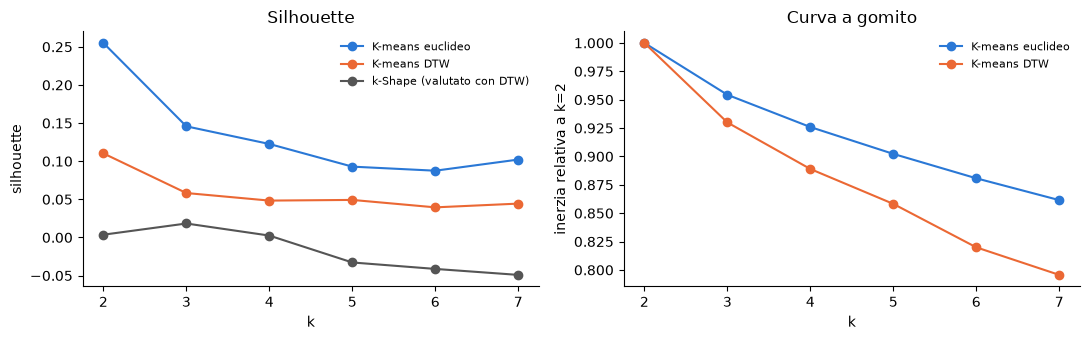

In [63]:
def k_selection():
    rows = []
    for k in K_RANGE:
        t0 = time.perf_counter()
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_lvl)
        sil_km = silhouette_score(X_lvl, km.labels_, sample_size=3000, random_state=SEED)
        dt = TimeSeriesKMeans(n_clusters=k, metric='dtw', metric_params=dtw_params, max_iter=10, max_iter_barycenter=5,
                              n_jobs=-1, random_state=SEED).fit(X_shape[sample, :, None])
        sil_dt = silhouette_score(D_dtw_s, dt.labels_, metric='precomputed')
        ks = KShape(n_clusters=k, n_init=2, max_iter=30, random_state=SEED).fit(X_shape_scaled[sample])
        sil_ks = silhouette_score(D_dtw_s, ks.labels_, metric='precomputed')
        rows.append({'k': k, 'silhouette kmeans (eucl.)': sil_km, 'inerzia kmeans': km.inertia_, 'silhouette DTW': sil_dt,
                     'inerzia DTW': dt.inertia_, 'silhouette kShape (su DTW)': sil_ks, 'sec': time.perf_counter() - t0})
        print(rows[-1], flush=True)
    return pd.DataFrame(rows)

k_table = cached('k_selection', k_selection)
print(k_table.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_table.k, k_table['silhouette kmeans (eucl.)'], marker='o', color=C0, label='K-means euclideo')
axes[0].plot(k_table.k, k_table['silhouette DTW'], marker='o', color=C1, label='K-means DTW')
axes[0].plot(k_table.k, k_table['silhouette kShape (su DTW)'], marker='o', color='#555555', label='k-Shape (valutato con DTW)')
axes[0].set_xlabel('k'); axes[0].set_ylabel('silhouette'); axes[0].legend(frameon=False, fontsize=8); axes[0].set_title('Silhouette')
axes[1].plot(k_table.k, k_table['inerzia kmeans'] / k_table['inerzia kmeans'].iloc[0], marker='o', color=C0, label='K-means euclideo')
axes[1].plot(k_table.k, k_table['inerzia DTW'] / k_table['inerzia DTW'].iloc[0], marker='o', color=C1, label='K-means DTW')
axes[1].set_xlabel('k'); axes[1].set_ylabel('inerzia relativa a k=2'); axes[1].legend(frameon=False, fontsize=8); axes[1].set_title('Curva a gomito')
for a_ in axes:
    a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

In [64]:
K_KM, K_DTW, K_KS = int(k_table.loc[k_table['silhouette kmeans (eucl.)'].idxmax(), 'k']), int(k_table.loc[k_table['silhouette DTW'].idxmax(), 'k']), int(k_table.loc[k_table['silhouette kShape (su DTW)'].idxmax(), 'k'])
print('k scelti con la silhouette:', K_KM, K_DTW, K_KS)

km_final = KMeans(n_clusters=K_KM, n_init=20, random_state=SEED).fit(X_lvl)
def fit_dtw():
    model = TimeSeriesKMeans(n_clusters=K_DTW, metric='dtw', metric_params=dtw_params, max_iter=10, max_iter_barycenter=5,
                             n_jobs=-1, random_state=SEED).fit(X_shape[sample, :, None])
    return model.cluster_centers_, model.predict(X_shape[:, :, None])
def fit_kshape():
    model = KShape(n_clusters=K_KS, n_init=3, max_iter=50, random_state=SEED).fit(X_shape_scaled)
    return model.cluster_centers_, model.labels_
dtw_centers, dtw_labels = cached(f'dtw_final_k{K_DTW}', fit_dtw)
ks_centers, ks_labels = cached(f'kshape_final_k{K_KS}', fit_kshape)
clusterings = {'K-means euclideo': km_final.labels_, 'K-means DTW': dtw_labels, 'k-Shape': ks_labels}

k scelti con la silhouette: 2 2 3


In [65]:
X_clean = PREP['X_raw']
def describe_clusters(lab):
    rows = []
    for c_ in np.unique(lab):
        w = lab == c_
        by_id = pd.Series(y[w], index=ids[w]).groupby(level=0).first()
        e = enmo_clean[w]
        rows.append({'cluster': int(c_), 'finestre': int(w.sum()), 'id': by_id.size,
                     'classe 1 (finestre)': round(y[w].mean(), 3),
                     'enmo medio': round(e.mean(), 4), 'enmo notte (0-40)': round(e[:, :40].mean(), 4),
                     'enmo giorno (60-180)': round(e[:, 60:180].mean(), 4),
                     'step del picco (mediana)': int(np.median(np.apply_along_axis(lambda s: np.convolve(s, np.ones(12) / 12, 'valid').argmax(), 1, e))),
                     'log-luce media': round(X_clean[w, 2].mean(), 2)})
    return pd.DataFrame(rows)

def label_permutation(lab, n_perm=2000, seed=SEED):
    """Associazione cluster-classe con test a permutazione PER ID: le etichette vengono scambiate fra soggetti, non fra finestre."""
    rng = np.random.default_rng(seed)
    uid, inv = np.unique(ids, return_inverse=True)
    y_id = pd.Series(y, index=ids).groupby(level=0).first().reindex(uid).values
    obs = normalized_mutual_info_score(y, lab)
    null = [normalized_mutual_info_score(rng.permutation(y_id)[inv], lab) for _ in range(n_perm)]
    return obs, float((1 + (np.array(null) >= obs).sum()) / (n_perm + 1))

def id_consistency(lab, seed=SEED, n_perm=200):
    """Quota media di finestre di un id nel suo cluster più frequente (solo id con almeno 5 finestre), contro una permutazione delle finestre."""
    multi = meta.groupby('id').size(); multi = set(multi[multi >= 5].index)
    def f(l):
        s = pd.DataFrame({'id': ids, 'l': l})
        s = s[s.id.isin(multi)]
        return s.groupby('id')['l'].agg(lambda v: v.value_counts(normalize=True).iloc[0]).mean()
    rng = np.random.default_rng(seed)
    return f(lab), float(np.mean([f(rng.permutation(lab)) for _ in range(n_perm)]))

for name, lab in clusterings.items():
    print(f"\n=== {name} (k={len(np.unique(lab))})")
    print(describe_clusters(lab).to_string(index=False))
    nmi, p = label_permutation(lab)
    cons, cons0 = id_consistency(lab)
    print(f"ARI con la classe: {adjusted_rand_score(y, lab):.4f}  |  NMI con la classe: {nmi:.4f}  (p per id = {p:.3f})")
    print(f"coerenza per id: {cons:.3f}  contro {cons0:.3f} se le finestre fossero assegnate a caso")
    wd = pd.crosstab(lab, meta['weekday'].isin([6, 7]).values, normalize='index')[True].round(3)
    print("quota weekday 6-7 per cluster:", wd.to_dict())

km3 = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(X_lvl).labels_
print("\nSensibilita': K-means euclideo con k=3")
print(describe_clusters(km3).to_string(index=False))
nmi3, p3 = label_permutation(km3)
print(f"NMI con la classe: {nmi3:.4f}  (p per id = {p3:.4f})")

names = list(clusterings)
print("\nARI fra gli algoritmi:")
for a_ in range(3):
    for b_ in range(a_ + 1, 3):
        print(f"  {names[a_]} vs {names[b_]}: {adjusted_rand_score(clusterings[names[a_]], clusterings[names[b_]]):.3f}")


=== K-means euclideo (k=2)
 cluster  finestre  id  classe 1 (finestre)  enmo medio  enmo notte (0-40)  enmo giorno (60-180)  step del picco (mediana)  log-luce media
       0      2990 316                0.383      0.0465             0.0231                0.0553                       113            2.34
       1      1276 196                0.206      0.0871             0.0253                0.1130                       128            2.63


ARI con la classe: -0.0191  |  NMI con la classe: 0.0250  (p per id = 0.000)
coerenza per id: 0.802  contro 0.709 se le finestre fossero assegnate a caso
quota weekday 6-7 per cluster: {0: 0.292, 1: 0.248}

=== K-means DTW (k=2)
 cluster  finestre  id  classe 1 (finestre)  enmo medio  enmo notte (0-40)  enmo giorno (60-180)  step del picco (mediana)  log-luce media
       0      2268 294                0.301      0.0583             0.0202                0.0727                       143            2.41
       1      1998 269                0.363      0.0589             0.0278                0.0724                        89            2.46


ARI con la classe: 0.0063  |  NMI con la classe: 0.0033  (p per id = 0.005)
coerenza per id: 0.659  contro 0.604 se le finestre fossero assegnate a caso
quota weekday 6-7 per cluster: {0: 0.307, 1: 0.247}

=== k-Shape (k=3)
 cluster  finestre  id  classe 1 (finestre)  enmo medio  enmo notte (0-40)  enmo giorno (60-180)  step del picco (mediana)  log-luce media
       0      1644 252                0.360      0.0560             0.0269                0.0667                        95            2.40
       1      1028 244                0.322      0.0595             0.0220                0.0755                       107            2.48
       2      1594 274                0.304      0.0607             0.0217                0.0767                       136            2.43


ARI con la classe: 0.0005  |  NMI con la classe: 0.0016  (p per id = 0.026)
coerenza per id: 0.508  contro 0.477 se le finestre fossero assegnate a caso
quota weekday 6-7 per cluster: {0: 0.211, 1: 0.396, 2: 0.274}

Sensibilita': K-means euclideo con k=3
 cluster  finestre  id  classe 1 (finestre)  enmo medio  enmo notte (0-40)  enmo giorno (60-180)  step del picco (mediana)  log-luce media
       0       516 136                0.174      0.0967             0.0223                0.1283                       148            2.70
       1      1476 218                0.250      0.0719             0.0281                0.0898                       104            2.50
       2      2274 296                0.417      0.0414             0.0213                0.0487                       121            2.32


NMI con la classe: 0.0269  (p per id = 0.0005)

ARI fra gli algoritmi:
  K-means euclideo vs K-means DTW: 0.000
  K-means euclideo vs k-Shape: 0.010
  K-means DTW vs k-Shape: 0.057


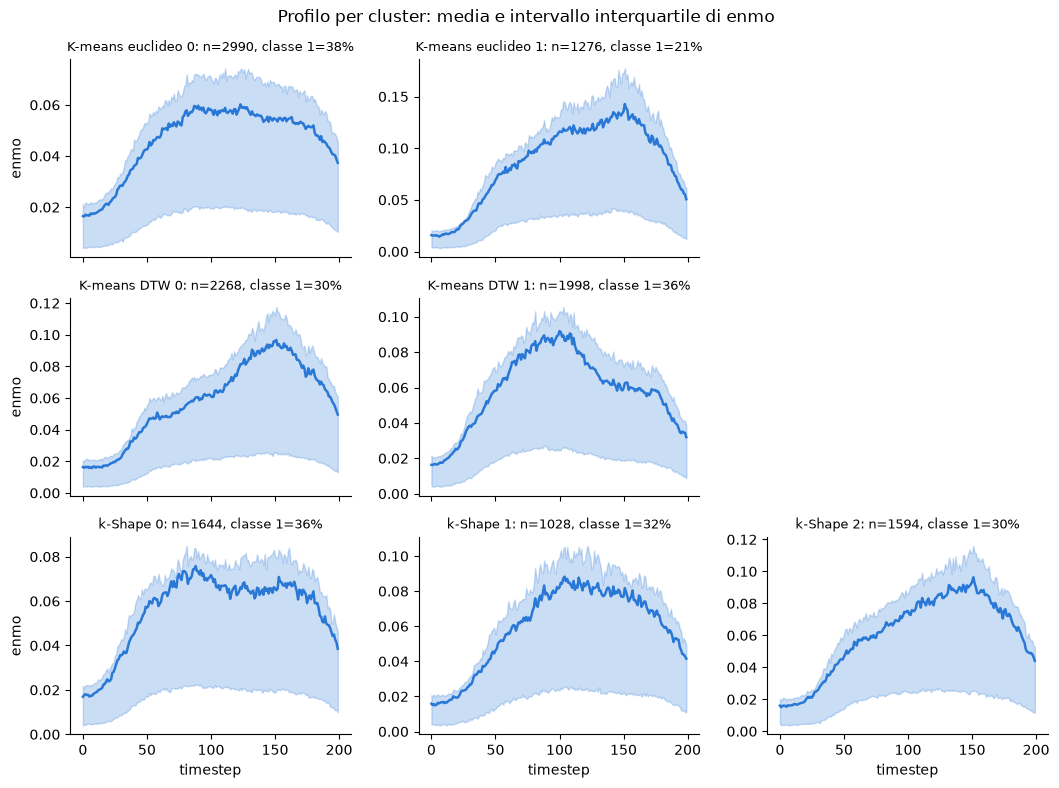

In [66]:
fig, axes = plt.subplots(3, max(K_KM, K_DTW, K_KS), figsize=(3.6 * max(K_KM, K_DTW, K_KS), 8), sharex=True, squeeze=False)
for row, (name, lab) in enumerate(clusterings.items()):
    for col in range(axes.shape[1]):
        ax = axes[row, col]
        if col >= len(np.unique(lab)):
            ax.axis('off'); continue
        w = lab == col
        e = enmo_clean[w]
        ax.fill_between(np.arange(200), np.quantile(e, 0.25, axis=0), np.quantile(e, 0.75, axis=0), color=C0, alpha=0.25)
        ax.plot(e.mean(axis=0), color=C0, linewidth=1.8)
        ax.set_title(f'{name} {col}: n={w.sum()}, classe 1={y[w].mean():.0%}', fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)
    axes[row, 0].set_ylabel('enmo')
for ax in axes[-1]:
    ax.set_xlabel('timestep')
plt.suptitle('Profilo per cluster: media e intervallo interquartile di enmo')
plt.tight_layout(); plt.show()

### Visualizzazione con riduzione dimensionale

Usiamo due tecniche con ipotesi diverse sullo stesso campione di 1500 finestre:

- **PCA**, lineare: conserva la varianza globale e permette di leggere gli assi;
- **t-SNE**, non lineare: conserva i vicinati locali. Per il K-means usa la distanza euclidea, per DTW e k-Shape la matrice DTW precalcolata, così la mappa riflette la distanza del clustering.

PCA varianza spiegata, livello: [0.181 0.077 0.06  0.053 0.043] | forma: [0.085 0.065 0.058 0.049 0.046]
correlazione PC1 (livello) con enmo medio: 0.97


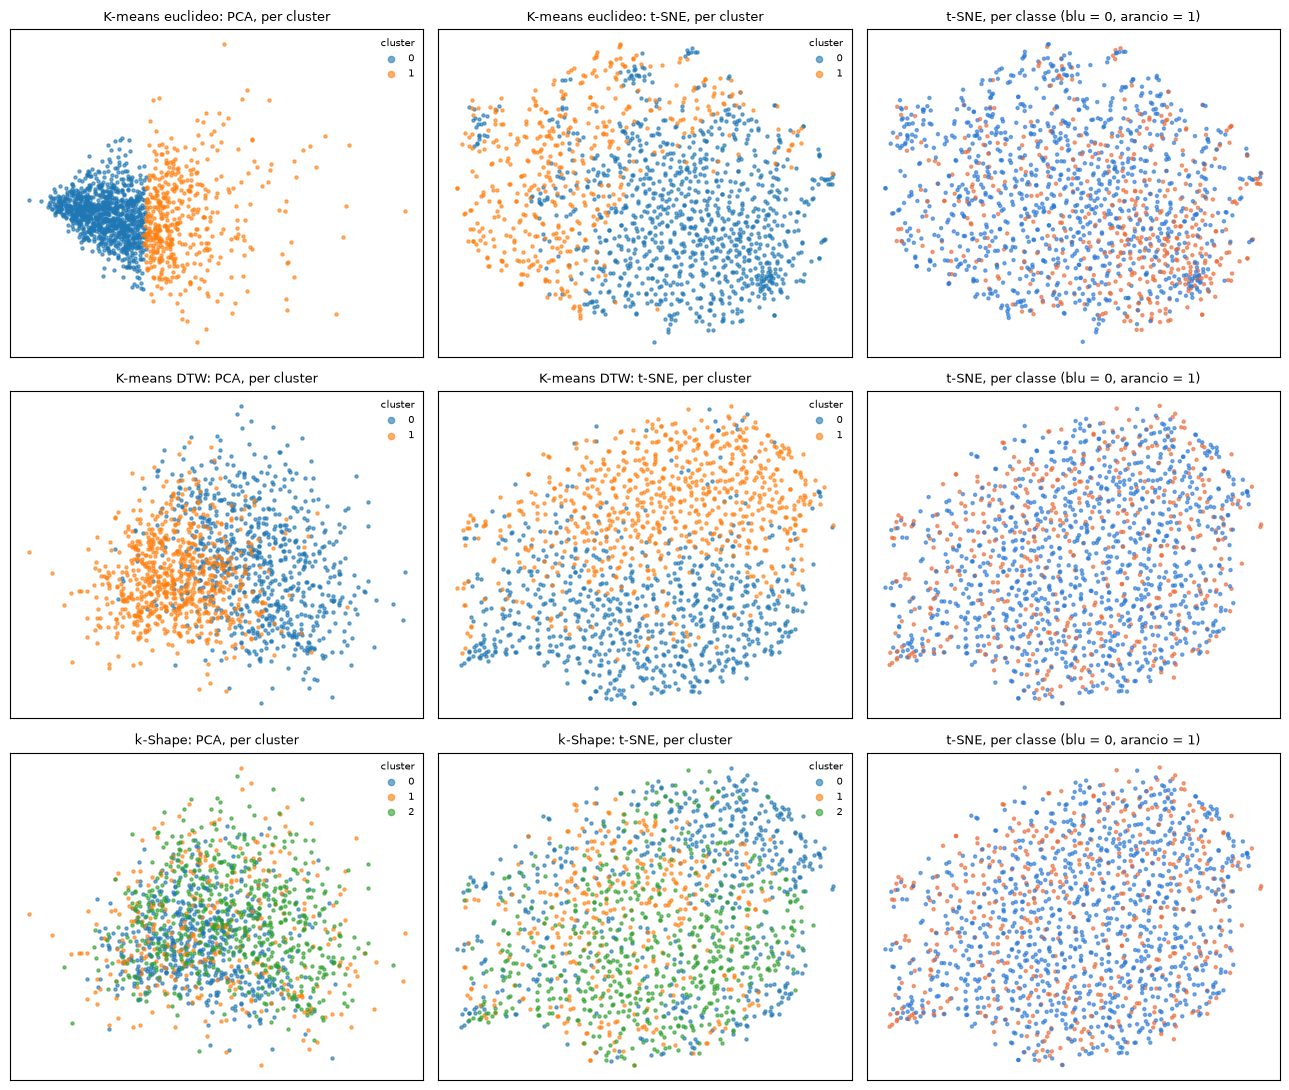

silhouette finali sul campione:
  K-means euclideo: 0.244
  K-means DTW: 0.11
  k-Shape (su DTW): -0.0


In [67]:
pca_lvl = PCA(n_components=5, random_state=SEED).fit(X_lvl)
Z_pca_lvl = pca_lvl.transform(X_lvl[sample])
pca_shape = PCA(n_components=5, random_state=SEED).fit(X_shape)
Z_pca_shape = pca_shape.transform(X_shape[sample])
print("PCA varianza spiegata, livello:", pca_lvl.explained_variance_ratio_.round(3), "| forma:", pca_shape.explained_variance_ratio_.round(3))
print("correlazione PC1 (livello) con enmo medio:", round(np.corrcoef(Z_pca_lvl[:, 0], enmo_clean[sample].mean(axis=1))[0, 1], 3))

Z_tsne_lvl = cached('tsne_lvl', lambda: TSNE(perplexity=30, init='pca', random_state=SEED).fit_transform(X_lvl[sample]))
Z_tsne_dtw = cached('tsne_dtw', lambda: TSNE(perplexity=30, metric='precomputed', init='random', random_state=SEED).fit_transform(D_dtw_s))

panels = [('K-means euclideo', Z_pca_lvl, Z_tsne_lvl), ('K-means DTW', Z_pca_shape, Z_tsne_dtw), ('k-Shape', Z_pca_shape, Z_tsne_dtw)]
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
cmap = plt.get_cmap('tab10')
for row, (name, zp, zt) in enumerate(panels):
    lab = clusterings[name][sample]
    for col, (z, t_) in enumerate([(zp, 'PCA'), (zt, 't-SNE')]):
        for c_ in np.unique(lab):
            axes[row, col].scatter(z[lab == c_, 0], z[lab == c_, 1], s=5, alpha=0.6, color=cmap(int(c_)), label=str(c_))
        axes[row, col].set_title(f'{name}: {t_}, per cluster', fontsize=9)
        axes[row, col].legend(frameon=False, fontsize=7, markerscale=2, title='cluster', title_fontsize=7)
    axes[row, 2].scatter(zt[:, 0], zt[:, 1], s=5, alpha=0.6, c=np.where(y[sample] == 1, C1, C0))
    axes[row, 2].set_title('t-SNE, per classe (blu = 0, arancio = 1)', fontsize=9)
    for a_ in axes[row]:
        a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()

# separazione misurata nello spazio originale, non a occhio nella mappa
print("silhouette finali sul campione:")
print("  K-means euclideo:", round(silhouette_score(X_lvl[sample], km_final.labels_[sample]), 3))
print("  K-means DTW:", round(silhouette_score(D_dtw_s, dtw_labels[sample], metric='precomputed'), 3))
print("  k-Shape (su DTW):", round(silhouette_score(D_dtw_s, ks_labels[sample], metric='precomputed'), 3))

**Risultato:**

- **Struttura debole.** La silhouette è massima a k=2 per K-means euclideo (0.255) e DTW (0.110) e a k=3 per k-Shape (0.018, praticamente zero). Non è una scelta netta: non emergono gruppi naturali. Lo confermano le mappe: t-SNE mostra una nuvola continua e PCA divide un unico ammasso con un taglio lungo PC1. I cluster sono **partizioni di un continuo**, non tipi distinti di giornata.
- **K-means euclideo separa il livello.** PC1 spiega il 18% della varianza e correla 0.97 con l'enmo medio. Il cluster 1 (1276 finestre) è attivo di giorno il doppio del cluster 0 (0.113 contro 0.055), mentre di notte i due quasi coincidono (0.025 contro 0.023). È il solo risultato con un legame apprezzabile con la classe: **38% di classe 1 contro 21%** (NMI 0.025, p per id = 0.0005). Con k=3 il gradiente resta: 42%, 25%, 17%.
- **DTW e k-Shape separano la forma, cioè il momento del picco.** Con DTW un cluster ha il picco più tardi (step mediano 143) e l'altro prima (89), con livello medio identico (0.058 e 0.059). k-Shape dà una suddivisione simile su tre gruppi (picco a 95, 107, 136). Il legame con la classe è minimo (30% contro 36%, NMI 0.003, p=0.005; k-Shape NMI 0.002, p=0.03).
- **Altri legami.** Il cluster di k-Shape con picco a 107 ha il 40% delle finestre in `weekday` 6-7, contro il 21% del cluster con picco a 95 e il 29% atteso per caso: la forma della giornata sembra dipendere più dal giorno della settimana che dalla classe. Il legame è descrittivo e assume che 6-7 siano sabato e domenica, codifica che non abbiamo potuto verificare.
- **Soggetti.** Le finestre di uno stesso id tendono a stare insieme nel clustering di livello (0.80 contro 0.71 atteso per caso), poco in quelli di forma (0.66 contro 0.60 con DTW, 0.51 contro 0.48 con k-Shape). Il livello è quindi più una caratteristica del soggetto, la forma più della singola giornata.
- **Similarità e differenze fra algoritmi.** I due gruppi di metodi guardano aspetti diversi e non concordano: ARI 0.000 fra K-means euclideo e DTW, 0.010 con k-Shape. DTW e k-Shape, entrambi sulla forma, concordano poco (ARI 0.057), altro segno di assenza di gruppi naturali.

**Conseguenza per la classificazione:** il segnale sulla classe dovrebbe stare nel livello di attività più che nella forma.